In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(r"C:\Users\Shashank\Downloads\Projects\Predictive_Maintenance_Intelligence\data\raw\ai4i2020.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:
# =====================================================
# PHASE 3: DATA PREPROCESSING
# STEP 1: CREATE PREPROCESSING DATASET
# =====================================================

import pandas as pd
import numpy as np

# Define input features
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

categorical_features = [
    "Type"
]

# Define target variable
target = "Machine failure"

# Select model input features
selected_features = (
    numerical_features + categorical_features
)

# Create independent variables
X = df[selected_features].copy()

# Create dependent variable
y = df[target].copy()

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Feature Dataset Shape: (10000, 6)
Target Dataset Shape: (10000,)

Input Features:
   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.1                    308.6                    1551   
1                298.2                    308.7                    1408   
2                298.1                    308.5                    1498   
3                298.2                    308.6                    1433   
4                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min] Type  
0         42.8                0    M  
1         46.3                3    L  
2         49.4                5    L  
3         39.5                7    L  
4         40.0                9    L  

Target Values:
0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64


In [4]:
# =====================================================
# STEP 2: DUPLICATE VALIDATION
# =====================================================

print("Duplicate Records:", X.duplicated().sum())

print("Duplicate Target Records:", y.duplicated().sum())

Duplicate Records: 0
Duplicate Target Records: 9998


In [5]:
# =====================================================
# STEP 3: MISSING VALUE ANALYSIS
# =====================================================

missing_analysis = pd.DataFrame({
    "Missing Count": X.isnull().sum(),
    "Missing Percentage": (
        X.isnull().sum() / len(X)
    ) * 100
})

missing_analysis

,Missing Count,Missing Percentage
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Type,0,0.0


In [6]:
# =====================================================
# STEP 4: TARGET CONSISTENCY VALIDATION
# =====================================================

failure_columns = [
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

failure_mode_present = df[
    failure_columns
].any(axis=1)

inconsistent_records = df[
    (df["Machine failure"] == 0) &
    (failure_mode_present)
]

print(
    "Inconsistent Records:",
    len(inconsistent_records)
)

print(
    "Original Machine Failures:",
    y.sum()
)

print(
    "Records with Failure Mode Indicators:",
    failure_mode_present.sum()
)

Inconsistent Records: 18
Original Machine Failures: 339
Records with Failure Mode Indicators: 348


In [7]:
# =====================================================
# STEP 5: FEATURE SELECTION VALIDATION
# =====================================================

print("Selected Input Features:")
print(X.columns.tolist())

print("\nExcluded Identifier Columns:")
print(["UDI", "Product ID"])

print("\nExcluded Failure Indicators:")
print(failure_columns)

print("\nTarget Variable:")
print(target)

Selected Input Features:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type']

Excluded Identifier Columns:
['UDI', 'Product ID']

Excluded Failure Indicators:
['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Target Variable:
Machine failure


In [8]:
# =====================================================
# STEP 8: TRAIN TEST SPLIT
# =====================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (8000, 6)
Testing Features: (2000, 6)
Training Target: (8000,)
Testing Target: (2000,)

Training Target Distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing Target Distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [9]:
# =====================================================
# STEP 9: AUTOMATED PREPROCESSING PIPELINE
# =====================================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
# =====================================================
# STEP 10: FIT AND TRANSFORM DATA
# =====================================================

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Data Processed Successfully!")
print("Testing Data Processed Successfully!")

print("\nTraining Processed Shape:",
      X_train_processed.shape)

print("Testing Processed Shape:",
      X_test_processed.shape)

Training Data Processed Successfully!
Testing Data Processed Successfully!

Training Processed Shape: (8000, 8)
Testing Processed Shape: (2000, 8)


In [11]:
# =====================================================
# STEP 11: VALIDATE PROCESSED DATA
# =====================================================

feature_names = preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed Training Dataset:")
display(X_train_processed_df.head())

print("\nProcessed Testing Dataset:")
display(X_test_processed_df.head())

Processed Training Dataset:


,numerical__Air temperature [K],numerical__Process temperature [K],numerical__Rotational speed [rpm],numerical__Torque [Nm],numerical__Tool wear [min],categorical__Type_H,categorical__Type_L,categorical__Type_M
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,0.0,0.0,1.0
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0.0,0.0,1.0
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0.0,0.0,1.0
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.0,1.0,0.0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0.0,1.0,0.0



Processed Testing Dataset:


,numerical__Air temperature [K],numerical__Process temperature [K],numerical__Rotational speed [rpm],numerical__Torque [Nm],numerical__Tool wear [min],categorical__Type_H,categorical__Type_L,categorical__Type_M
2997,0.247681,-0.139294,-1.073963,2.265378,0.712410,0.0,1.0,0.0
4871,1.850310,1.618248,-0.145641,0.009646,0.429427,0.0,1.0,0.0
3858,1.249324,0.942270,0.108543,-0.239882,1.592802,0.0,1.0,0.0
951,-2.206344,-2.505215,-0.167744,-0.419543,-0.749670,1.0,0.0,0.0
6463,0.247681,-0.004098,-1.002129,2.035812,-0.089376,1.0,0.0,0.0


In [14]:
os.makedirs("../models", exist_ok=True)

In [15]:
# =====================================================
# STEP 12: SAVE PROCESSED DATA
# =====================================================

import os
import joblib

# Create processed data directory
os.makedirs("../data/processed", exist_ok=True)

# Save datasets
X_train_processed_df.to_csv(
    "../data/processed/X_train.csv",
    index=False
)

X_test_processed_df.to_csv(
    "../data/processed/X_test.csv",
    index=False
)

y_train.to_csv(
    "../data/processed/y_train.csv",
    index=False
)

y_test.to_csv(
    "../data/processed/y_test.csv",
    index=False
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "../models/preprocessor.pkl"
)

print("All processed datasets saved successfully!")

All processed datasets saved successfully!


In [16]:
# =====================================================
# PHASE 4: FEATURE ENGINEERING
# STEP 1: VERIFY ORIGINAL DATA
# =====================================================

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nOriginal Training Features:")
print(X_train.columns.tolist())

Training Data: (8000, 6)
Testing Data: (2000, 6)

Training Target: (8000,)
Testing Target: (2000,)

Original Training Features:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type']


In [17]:
# =====================================================
# STEP 3: FEATURE ENGINEERING FUNCTION
# =====================================================

def create_features(data):

    data = data.copy()

    # Feature 1: Temperature difference
    data["Temperature Difference [K]"] = (
        data["Process temperature [K]"] -
        data["Air temperature [K]"]
    )

    # Feature 2: Mechanical power in kW
    data["Mechanical Power [kW]"] = (
        data["Torque [Nm]"] *
        data["Rotational speed [rpm]"] *
        (2 * np.pi / 60)
    ) / 1000

    return data


print("Feature engineering function created successfully!")

Feature engineering function created successfully!


In [18]:
# =====================================================
# STEP 4: APPLY FEATURE ENGINEERING
# =====================================================

X_train_fe = create_features(X_train)

X_test_fe = create_features(X_test)

print("Training Features:", X_train_fe.shape)

print("Testing Features:", X_test_fe.shape)

print("\nNew Training Dataset:")
display(X_train_fe.head())

Training Features: (8000, 8)
Testing Features: (2000, 8)

New Training Dataset:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type,Temperature Difference [K],Mechanical Power [kW]
4058,302.0,310.9,1456,47.2,54,M,8.9,7.196677
1221,297.0,308.3,1399,46.4,132,M,11.3,6.797736
6895,301.0,311.6,1357,45.6,137,M,10.6,6.479975
9863,298.9,309.8,1411,56.3,84,L,10.9,8.318864
8711,297.1,308.5,1733,28.7,50,L,11.4,5.208457


In [19]:
# =====================================================
# STEP 5: ENGINEERED FEATURE SUMMARY
# =====================================================

engineered_features = [
    "Temperature Difference [K]",
    "Mechanical Power [kW]"
]

engineered_summary = X_train_fe[
    engineered_features
].describe().T

engineered_summary

,count,mean,std,min,25%,50%,75%,max
Temperature Difference [K],8000.0,10.000613,0.999854,7.600000,9.300000,9.800000,11.000000,12.100000
Mechanical Power [kW],8000.0,6.282618,1.072419,1.148441,5.559606,6.272294,7.013867,10.469923


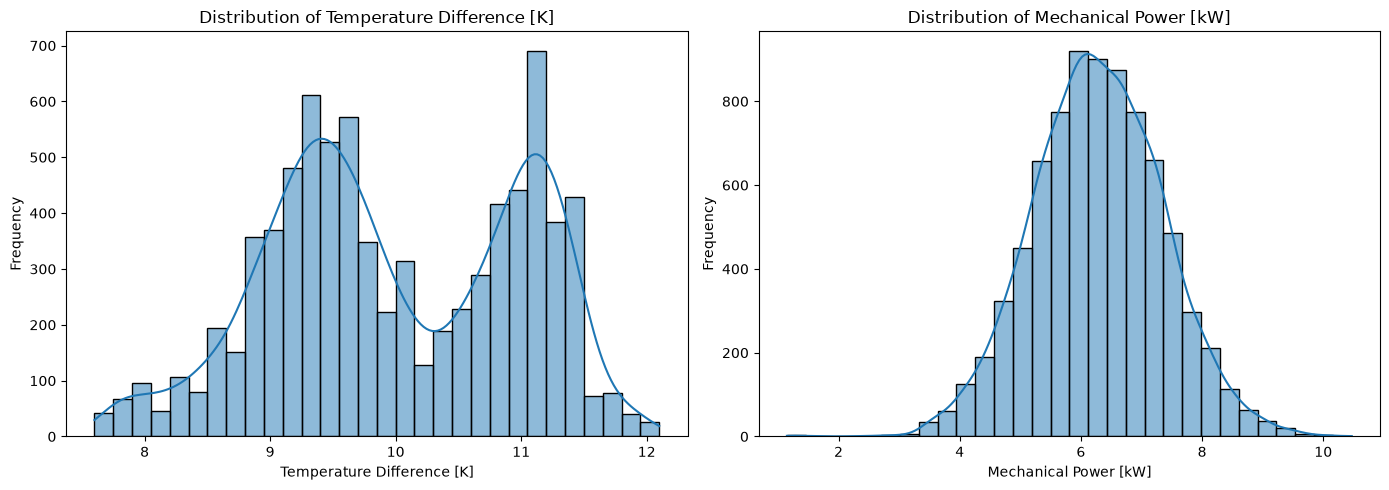

In [20]:
# =====================================================
# STEP 6.1: ENGINEERED FEATURE DISTRIBUTION
# =====================================================

plt.figure(figsize=(14, 5))

for i, col in enumerate(engineered_features, 1):

    plt.subplot(1, 2, i)

    sns.histplot(
        data=X_train_fe,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")

    plt.xlabel(col)

    plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

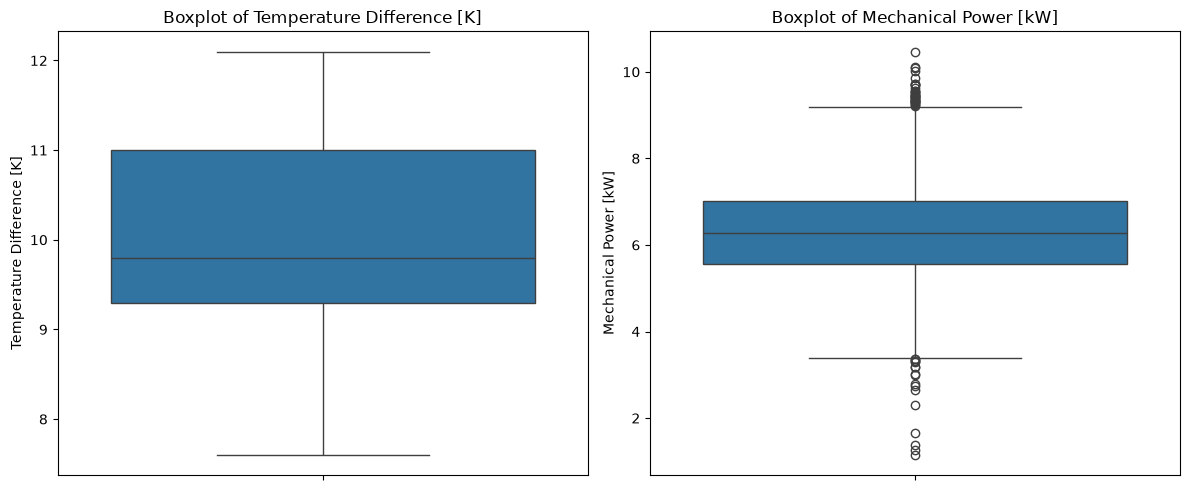

In [21]:
# =====================================================
# STEP 6.2: ENGINEERED FEATURE BOXPLOTS
# =====================================================

plt.figure(figsize=(12, 5))

for i, col in enumerate(engineered_features, 1):

    plt.subplot(1, 2, i)

    sns.boxplot(
        data=X_train_fe,
        y=col
    )

    plt.title(f"Boxplot of {col}")

plt.tight_layout()

plt.show()

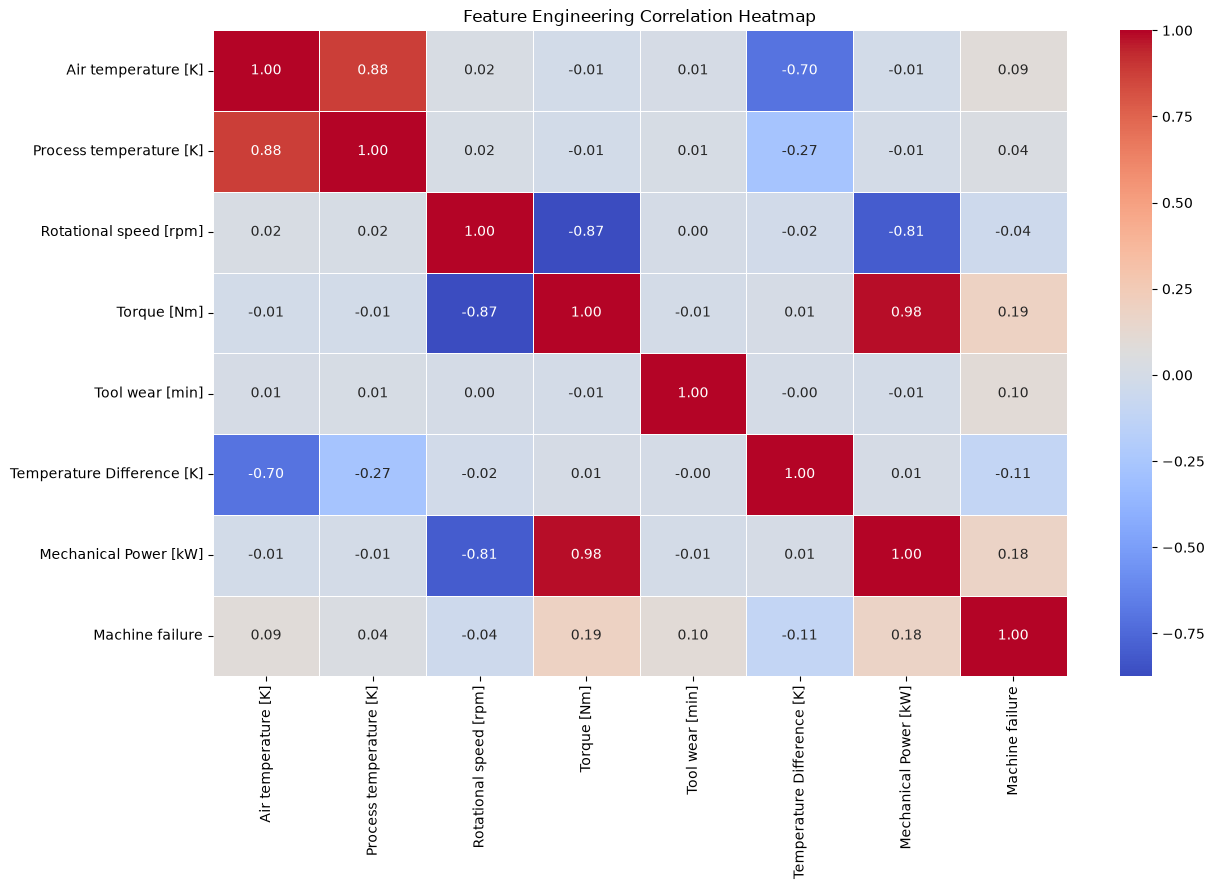

In [22]:
# =====================================================
# STEP 7: ENGINEERED FEATURE CORRELATION
# =====================================================

feature_analysis_df = X_train_fe[
    numerical_features + engineered_features
].copy()

feature_analysis_df["Machine failure"] = y_train

correlation_matrix_fe = feature_analysis_df.corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix_fe,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Engineering Correlation Heatmap")

plt.tight_layout()

plt.show()

In [23]:
# =====================================================
# STEP 8: ENGINEERED FEATURES VS MACHINE FAILURE
# =====================================================

engineered_comparison = X_train_fe[
    engineered_features
].groupby(y_train).mean().T

engineered_comparison.columns = [
    "No Failure",
    "Failure"
]

engineered_comparison["Difference"] = (
    engineered_comparison["Failure"] -
    engineered_comparison["No Failure"]
)

engineered_comparison

,No Failure,Failure,Difference
Temperature Difference [K],10.021452,9.406273,-0.615179
Mechanical Power [kW],6.247278,7.290524,1.043246


In [24]:
# =====================================================
# STEP 9: FINAL FEATURE SELECTION
# =====================================================

final_numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference [K]",
    "Mechanical Power [kW]"
]

final_categorical_features = [
    "Type"
]

final_features = (
    final_numerical_features +
    final_categorical_features
)

X_train_final = X_train_fe[final_features].copy()

X_test_final = X_test_fe[final_features].copy()

print("Final Training Shape:", X_train_final.shape)

print("Final Testing Shape:", X_test_final.shape)

print("\nFinal Features:")

for i, feature in enumerate(final_features, 1):
    print(f"{i}. {feature}")

Final Training Shape: (8000, 8)
Final Testing Shape: (2000, 8)

Final Features:
1. Air temperature [K]
2. Process temperature [K]
3. Rotational speed [rpm]
4. Torque [Nm]
5. Tool wear [min]
6. Temperature Difference [K]
7. Mechanical Power [kW]
8. Type


In [25]:
# =====================================================
# STEP 10: UPDATED PREPROCESSING PIPELINE
# =====================================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical pipeline
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical pipeline
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combined preprocessing
preprocessor_fe = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            final_numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            final_categorical_features
        )
    ]
)

print("Updated preprocessing pipeline created!")

Updated preprocessing pipeline created!


In [26]:
# =====================================================
# STEP 11: TRANSFORM ENGINEERED DATA
# =====================================================

# Fit on training data
X_train_final_processed = preprocessor_fe.fit_transform(
    X_train_final
)

# Transform testing data
X_test_final_processed = preprocessor_fe.transform(
    X_test_final
)

print(
    "Training Processed Shape:",
    X_train_final_processed.shape
)

print(
    "Testing Processed Shape:",
    X_test_final_processed.shape
)

Training Processed Shape: (8000, 10)
Testing Processed Shape: (2000, 10)


In [27]:
# =====================================================
# STEP 12: SAVE FEATURE ENGINEERING RESULTS
# =====================================================

import os
import joblib

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

# Get transformed feature names
processed_feature_names = (
    preprocessor_fe.get_feature_names_out()
)

# Convert to DataFrames
X_train_processed_fe = pd.DataFrame(
    X_train_final_processed,
    columns=processed_feature_names,
    index=X_train_final.index
)

X_test_processed_fe = pd.DataFrame(
    X_test_final_processed,
    columns=processed_feature_names,
    index=X_test_final.index
)

# Save engineered raw features
X_train_final.to_csv(
    "../data/processed/X_train_engineered.csv",
    index=False
)

X_test_final.to_csv(
    "../data/processed/X_test_engineered.csv",
    index=False
)

# Save transformed features
X_train_processed_fe.to_csv(
    "../data/processed/X_train_final.csv",
    index=False
)

X_test_processed_fe.to_csv(
    "../data/processed/X_test_final.csv",
    index=False
)

# Save targets
y_train.to_csv(
    "../data/processed/y_train.csv",
    index=False
)

y_test.to_csv(
    "../data/processed/y_test.csv",
    index=False
)

# Save updated preprocessing pipeline
joblib.dump(
    preprocessor_fe,
    "../models/preprocessor_fe.pkl"
)

print("Feature engineering completed!")
print("All datasets and preprocessing pipeline saved!")

Feature engineering completed!
All datasets and preprocessing pipeline saved!
